# Auswertung der Ergebnisse: Studie Teil 3

Vergleich von 3 Prompting-Strategien anhand von 2 Modellen. Ziel: Inhaltliche Verbesserung.

Modelle:
* NuExtract3-4B
* Qwen2.5-7B-instruct

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('ergebnisse_studie_teil3_CoT.csv', sep=';', decimal=',')

In [2]:
df.head(10)

,Run_ID,Modell,Artikel_ID,Strategie,Input_Token,Reasoning_Token,Output_Token,Laufzeit_in_s,JSON_parsbar,TP,FN,FP,Document_Perfect_Match,Artikelnummer?
0,1,NuExtract3,20323-000,Few-Shot-2 + Internal CoT,5744,775,1243,40.235,1,13,2,2,0,1
1,2,NuExtract3,20323-000,Few-Shot-4 + Internal CoT,8668,825,1267,42.806,1,14,1,0,0,1
2,3,NuExtract3,20323-000,Zero-Shot + Internal CoT,2774,721,1222,36.398,1,12,3,0,0,1
3,4,NuExtract3,40402-405,Few-Shot-2 + Internal CoT,4894,560,846,28.186,1,12,0,0,1,1
4,5,NuExtract3,40402-405,Few-Shot-4 + Internal CoT,7818,640,955,33.626,1,11,1,0,0,1
5,6,NuExtract3,40402-405,Zero-Shot + Internal CoT,1924,538,872,27.174,1,12,0,5,0,1
6,7,NuExtract3,40135-014,Few-Shot-2 + Internal CoT,4890,1028,1348,39.404,1,8,4,0,0,1
7,8,NuExtract3,40135-014,Few-Shot-4 + Internal CoT,7814,396,645,26.052,1,7,5,0,0,1
8,9,NuExtract3,40135-014,Zero-Shot + Internal CoT,1920,791,1117,31.476,1,12,0,2,0,1
9,10,NuExtract3,30160-875,Few-Shot-2 + Internal CoT,10485,1062,1905,117.979,1,8,2,9,0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Run_ID                  30 non-null     int64  
 1   Modell                  30 non-null     object 
 2   Artikel_ID              30 non-null     object 
 3   Strategie               30 non-null     object 
 4   Input_Token             30 non-null     int64  
 5   Reasoning_Token         30 non-null     int64  
 6   Output_Token            30 non-null     int64  
 7   Laufzeit_in_s           30 non-null     float64
 8   JSON_parsbar            30 non-null     int64  
 9   TP                      30 non-null     int64  
 10  FN                      30 non-null     int64  
 11  FP                      30 non-null     int64  
 12  Document_Perfect_Match  30 non-null     int64  
 13  Artikelnummer?          30 non-null     int64  
dtypes: float64(1), int64(10), object(3)
memory u

## Precision & Recall

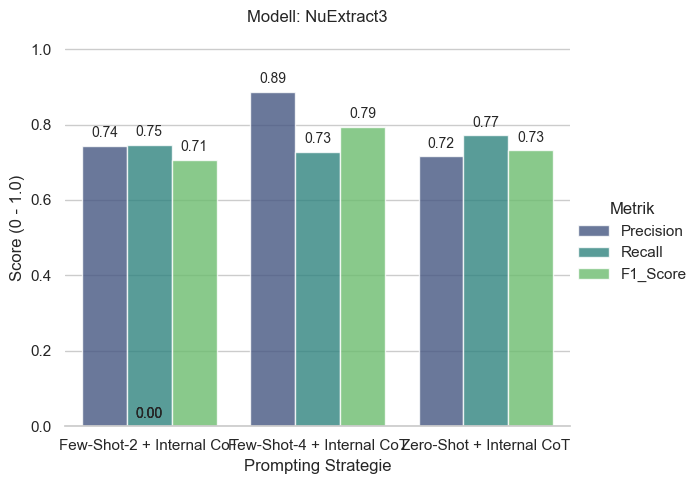

In [4]:
# 2. Metriken pro Zeile berechnen
# Division durch 0 abfangen (falls TP+FP oder TP+FN mal 0 sein sollten)
df['Precision'] = (df['TP'] / (df['TP'] + df['FP'])).fillna(0)
df['Recall'] = (df['TP'] / (df['TP'] + df['FN'])).fillna(0)
df['F1_Score'] = (2 * (df['Precision'] * df['Recall']) / (df['Precision'] + df['Recall'])).fillna(0)

# 3. Durchschnitt (Macro-Average) pro Modell und Strategie berechnen
grouped = df.groupby(['Modell', 'Strategie'])[['Precision', 'Recall', 'F1_Score']].mean().reset_index()

# 4. Datenstruktur für Seaborn anpassen (Melting)
melted = grouped.melt(
    id_vars=['Modell', 'Strategie'], 
    value_vars=['Precision', 'Recall', 'F1_Score'], 
    var_name='Metrik', 
    value_name='Wert'
)

# 5. Visualisierung erstellen (Ein Plot pro Modell)
sns.set_theme(style="whitegrid")
g = sns.catplot(
    data=melted, 
    kind="bar",
    x="Strategie", 
    y="Wert", 
    hue="Metrik", 
    col="Modell",
    palette="viridis", 
    alpha=.8, 
    height=5, 
    aspect=1.2
)

# Design-Anpassungen
g.despine(left=True)
g.set_axis_labels("Prompting Strategie", "Score (0 - 1.0)")
g.set_titles("Modell: {col_name}")
g.set(ylim=(0, 1.05))

# Werte direkt über die Balken schreiben
for ax in g.axes.flat:
    for p in ax.patches:
        ax.annotate(format(p.get_height(), '.2f'), 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', 
                    xytext=(0, 9), 
                    textcoords='offset points',
                    fontsize=10)

plt.show()

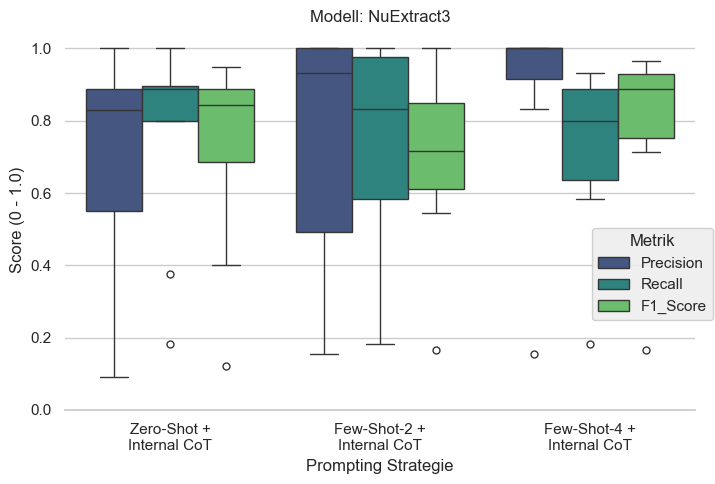

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
import textwrap

# 1 & 2. Metriken berechnen (wie bisher)
df['Precision'] = (df['TP'] / (df['TP'] + df['FP'])).fillna(0)
df['Recall'] = (df['TP'] / (df['TP'] + df['FN'])).fillna(0)
df['F1_Score'] = (2 * (df['Precision'] * df['Recall']) / (df['Precision'] + df['Recall'])).fillna(0)

strategy_order = ['Zero-Shot + Internal CoT', 'Few-Shot-2 + Internal CoT', 'Few-Shot-4 + Internal CoT']

# 3. WICHTIG: KEIN Groupby.mean() durchführen! 
# Wir schmelzen direkt das rohe DataFrame, damit Seaborn alle Werte kennt.
melted = df.melt(
    id_vars=['Modell', 'Strategie'], 
    value_vars=['Precision', 'Recall', 'F1_Score'], 
    var_name='Metrik', 
    value_name='Wert'
 )

# 4. Boxplot erstellen (Ein Plot pro Modell)
sns.set_theme(style="whitegrid")
g = sns.catplot(
    data=melted, 
    kind="box",      # <-- Hier auf 'box' umgestellt
    x="Strategie",
    order=strategy_order,
    y="Wert", 
    hue="Metrik", 
    col="Modell",
    palette="viridis", 
    height=5, 
    aspect=1.2
)

# Design-Anpassungen
g.despine(left=True)
g.set_axis_labels("Prompting Strategie", "Score (0 - 1.0)")
g.set_titles("Modell: {col_name}")
g.set(ylim=(0, 1.05))

# Legende mit dezenter grauer Fläche etwas nach unten verschieben
legend = g._legend
legend.set_bbox_to_anchor((1.0, 0.42))
legend.set_frame_on(True)
legend.get_frame().set_facecolor('#eeeeee')
legend.get_frame().set_edgecolor('#cccccc')
legend.get_frame().set_alpha(0.9)

# Lange Strategienamen umbrechen, damit die Beschriftungen nicht überlappen
for ax in g.axes.flat:
    ax.set_xticks(ax.get_xticks())
    labels = [textwrap.fill(label.get_text(), width=16) for label in ax.get_xticklabels()]
    ax.set_xticklabels(labels, rotation=0, ha='center')

plt.tight_layout()

plt.savefig("CoT.pdf", format="pdf", bbox_inches="tight")

plt.show()

**Präzision (Precision):** Wie sehr kannst du den Antworten des Modells vertrauen? Sie misst den Anteil der *korrekten* Extraktionen an *allen* Werten, die das Modell ausgegeben hat. Eine hohe Präzision bedeutet, dass das Modell kaum Dinge erfindet oder falsch zuordnet (wenig False Positives/Halluzinationen).

**Vollständigkeit (Recall):** Wie viel geht dir verloren? Der Recall misst den Anteil der korrekt gefundenen Werte an allen Informationen, die *tatsächlich im Dokument standen*. Ein hoher Recall bedeutet, dass das Modell kaum relevante Daten übersieht oder weglässt (wenig False Negatives).

**F1-Score:** Die goldene Mitte. Modelle neigen dazu, einen Trade-off einzugehen: Sie sind entweder extrem vorsichtig (hohe Präzision, schlechter Recall) oder raten wild drauflos, um ja nichts zu verpassen (hoher Recall, miese Präzision). Der F1-Score bildet das harmonische Mittel aus beiden Werten und gilt als die wichtigste Einzelmetrik, um die echte Gesamtleistung zu bewerten.

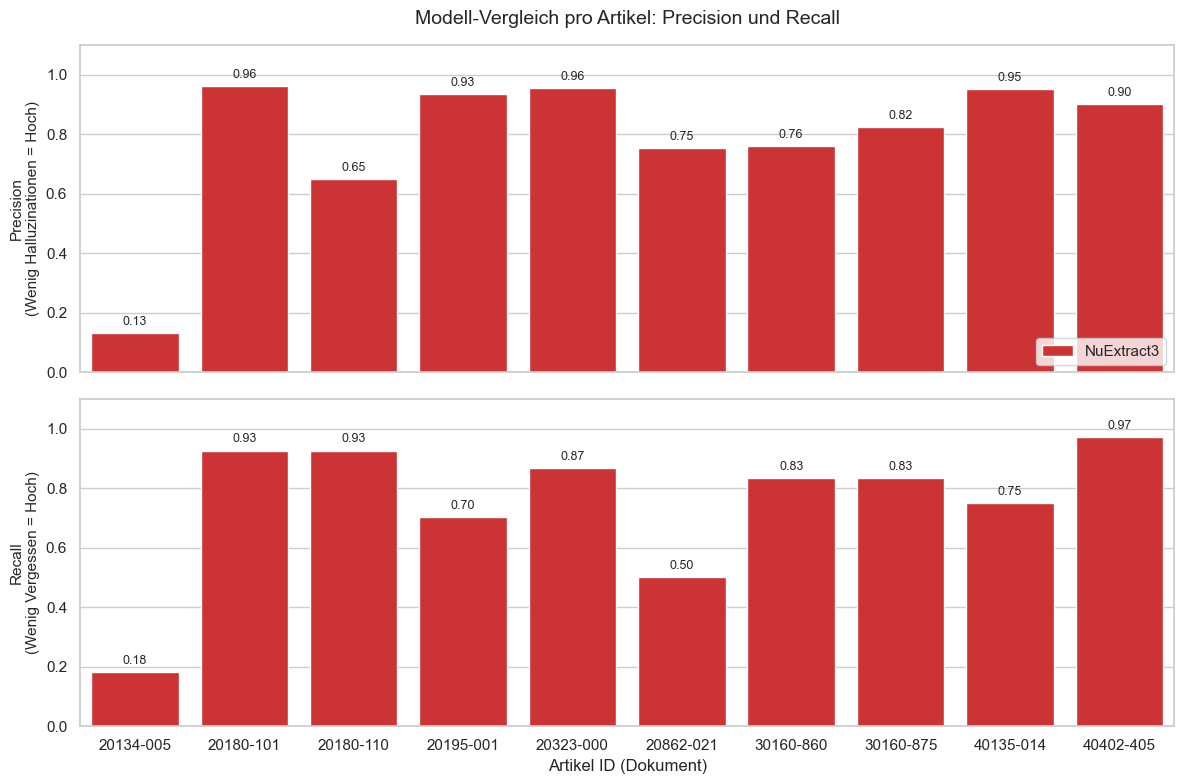

In [6]:
# 2. Precision und Recall berechnen
df['Precision'] = (df['TP'] / (df['TP'] + df['FP'])).fillna(0)
df['Recall'] = (df['TP'] / (df['TP'] + df['FN'])).fillna(0)

# 3. Aggregieren: Durchschnitt pro Artikel und Modell
grouped = df.groupby(['Artikel_ID', 'Modell'])[['Precision', 'Recall']].mean().reset_index()

# 4. Schaubild erstellen: 2 Plots übereinander (Subplots)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
sns.set_theme(style="whitegrid")

# Oberes Diagramm: Precision
sns.barplot(
    data=grouped, 
    x='Artikel_ID', 
    y='Precision', 
    hue='Modell', 
    ax=ax1, 
    palette='Set1'
)
ax1.set_title('Modell-Vergleich pro Artikel: Precision und Recall', fontsize=14, pad=15)
ax1.set_ylabel('Precision\n(Wenig Halluzinationen = Hoch)', fontsize=11)
ax1.set_ylim(0, 1.1)
ax1.legend(loc='lower right')

# Unteres Diagramm: Recall
sns.barplot(
    data=grouped, 
    x='Artikel_ID', 
    y='Recall', 
    hue='Modell', 
    ax=ax2, 
    palette='Set1'
)
ax2.set_ylabel('Recall\n(Wenig Vergessen = Hoch)', fontsize=11)
ax2.set_xlabel('Artikel ID (Dokument)', fontsize=12)
ax2.set_ylim(0, 1.1)

# Legende im unteren Diagramm ausblenden (da sie schon oben ist)
ax2.get_legend().remove()

# Werte über die Balken schreiben
for ax in [ax1, ax2]:
    for p in ax.patches:
        height = p.get_height()
        if pd.notna(height) and height > 0:
            ax.annotate(f'{height:.2f}', 
                        (p.get_x() + p.get_width() / 2., height), 
                        ha='center', va='center', 
                        xytext=(0, 8), 
                        textcoords='offset points',
                        fontsize=9)

plt.tight_layout()
plt.show()

In [7]:
df_s2 = pd.read_csv('ergebnisse_studie_teil2_prompting_strategien.csv', sep=';', decimal=',')
df_s3 = pd.read_csv('ergebnisse_studie_teil3_CoT.csv', sep=';', decimal=',')

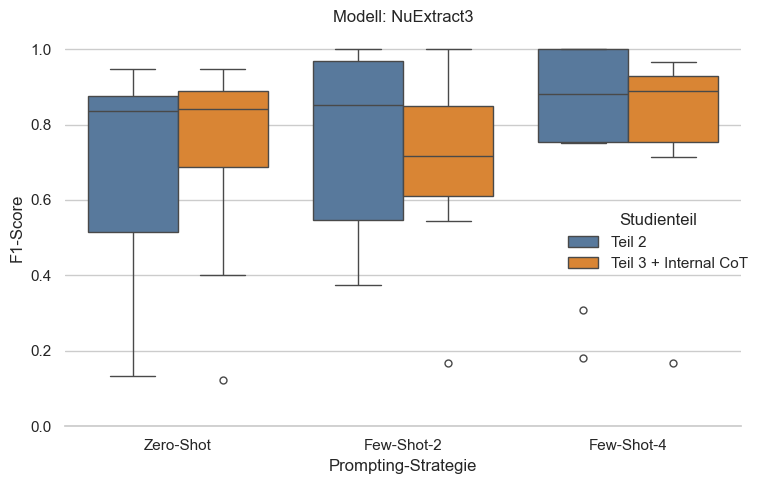

In [8]:
# F1-Scores aus Teil 2 und Teil 3 berechnen
for data in (df_s2, df_s3):
    data['Precision'] = (data['TP'] / (data['TP'] + data['FP'])).fillna(0)
    data['Recall'] = (data['TP'] / (data['TP'] + data['FN'])).fillna(0)
    data['F1_Score'] = (
        2 * data['Precision'] * data['Recall']
        / (data['Precision'] + data['Recall'])
    ).fillna(0)

df_s2_plot = df_s2[['Modell', 'Strategie', 'F1_Score']].copy()
df_s2_plot['Studienteil'] = 'Teil 2'

df_s3_plot = df_s3[['Modell', 'Strategie', 'F1_Score']].copy()
df_s3_plot['Studienteil'] = 'Teil 3 + Internal CoT'
df_s3_plot['Strategie'] = df_s3_plot['Strategie'].str.replace(
    ' + Internal CoT', '', regex=False
)

vergleich = pd.concat([df_s2_plot, df_s3_plot], ignore_index=True)
vergleich = vergleich[vergleich['Modell'] == 'NuExtract3']
strategie_order = ['Zero-Shot', 'Few-Shot-2', 'Few-Shot-4']
vergleich['Strategie'] = pd.Categorical(
    vergleich['Strategie'], categories=strategie_order, ordered=True
)

sns.set_theme(style='whitegrid')
g = sns.catplot(
    data=vergleich,
    kind='box',
    x='Strategie',
    y='F1_Score',
    hue='Studienteil',
    col='Modell',
    order=strategie_order,
    hue_order=['Teil 2', 'Teil 3 + Internal CoT'],
    palette={'Teil 2': '#4C78A8', 'Teil 3 + Internal CoT': '#F58518'},
    height=5,
    aspect=1.15,
    showfliers=True
)

g.set_axis_labels('Prompting-Strategie', 'F1-Score')
g.set_titles('Modell: {col_name}')
g.set(ylim=(0, 1.05))
g.despine(left=True)

plt.tight_layout()
plt.savefig('F1_Vergleich_Teil2_Teil3_CoT.pdf', format='pdf', bbox_inches='tight')
plt.show()

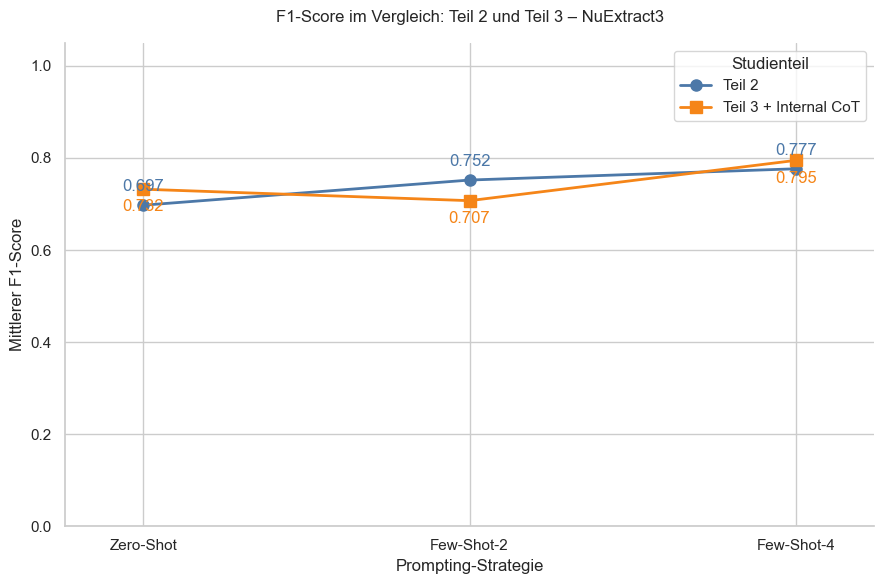

In [9]:
# Liniendiagramm: mittlerer F1-Score für Teil 2 und Teil 3.
# Gleiche Daten und Modellauswahl wie im Boxplot der vorherigen Zelle.
f1_verlauf = (
    vergleich.groupby(['Studienteil', 'Strategie'], observed=True)['F1_Score']
    .mean()
    .unstack('Strategie')
    .reindex(columns=strategie_order)
)

sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(9, 6))
for studienteil, farbe, marker in [
    ('Teil 2', '#4C78A8', 'o'),
    ('Teil 3 + Internal CoT', '#F58518', 's'),
]:
    werte = f1_verlauf.loc[studienteil]
    ax.plot(
        strategie_order, werte, label=studienteil,
        color=farbe, marker=marker, markersize=8, linewidth=2
    )
    for strategie, wert in werte.items():
        if pd.notna(wert):
            ax.annotate(
                f'{wert:.3f}', (strategie, wert),
                xytext=(0, 10 if studienteil == 'Teil 2' else -16),
                textcoords='offset points', ha='center', color=farbe
            )

ax.set_title('F1-Score im Vergleich: Teil 2 und Teil 3 – NuExtract3', pad=15)
ax.set_xlabel('Prompting-Strategie')
ax.set_ylabel('Mittlerer F1-Score')
ax.set_ylim(0, 1.05)
ax.margins(x=0.12)
ax.legend(title='Studienteil', loc='best')
sns.despine(ax=ax)
fig.tight_layout()
plt.savefig('F1_Vergleich_Teil2_Teil3_CoT_Liniendiagramm.pdf',
            format='pdf', bbox_inches='tight')
plt.show()
